In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/henryshan/starbucks/starbucks.csv


Dataset: /kaggle/input/datasets/henryshan/starbucks/starbucks.csv

First 5 Rows:
         Beverage_category       Beverage      Beverage_prep  Calories  \
0                   Coffee  Brewed Coffee              Short         3   
1                   Coffee  Brewed Coffee               Tall         4   
2                   Coffee  Brewed Coffee             Grande         5   
3                   Coffee  Brewed Coffee              Venti         5   
4  Classic Espresso Drinks    Caffè Latte  Short Nonfat Milk        70   

   Total Fat (g)  Trans Fat (g)   Saturated Fat (g)   Sodium (mg)  \
0            0.1             0.0                0.0             0   
1            0.1             0.0                0.0             0   
2            0.1             0.0                0.0             0   
3            0.1             0.0                0.0             0   
4            0.1             0.1                0.0             5   

    Total Carbohydrates (g)   Cholesterol (mg)   Dietary Fi

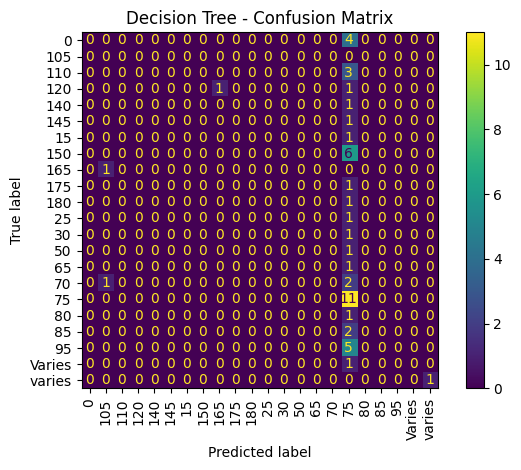

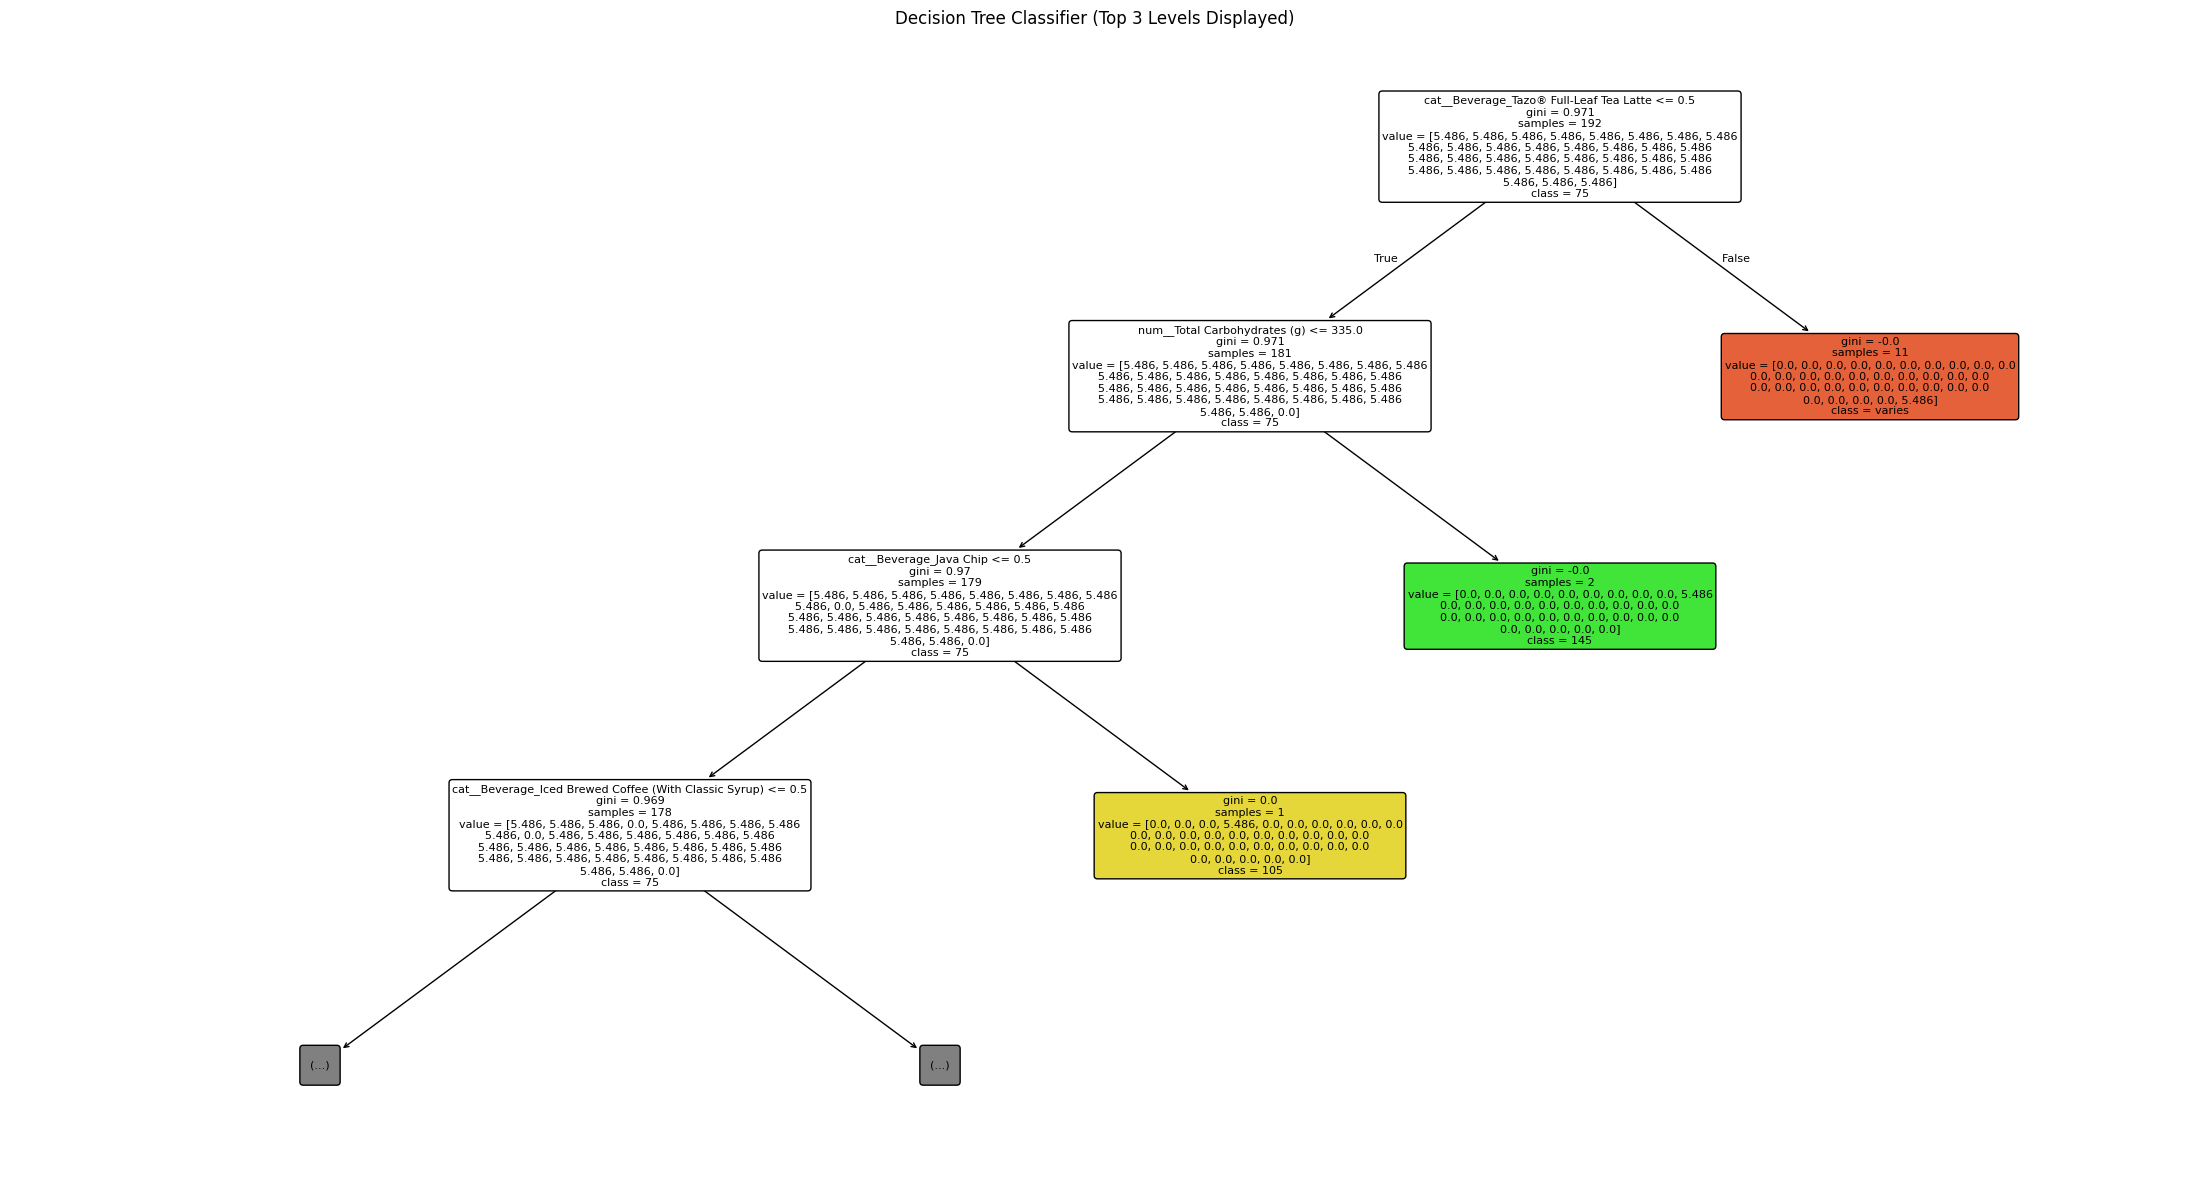


Top 10 Important Features:
cat__Beverage_Tazo® Full-Leaf Tea Latte                  0.167018
num__Total Carbohydrates (g)                             0.167018
num__Calories                                            0.167018
cat__Beverage_Iced Brewed Coffee (With Classic Syrup)    0.167018
cat__Beverage_Java Chip                                  0.167018
cat__Calcium (% DV)_2%                                   0.164910
num__Dietary Fibre (g)                                   0.000000
num__Sugars (g)                                          0.000000
num__Sodium (mg)                                         0.000000
num__Cholesterol (mg)                                    0.000000
dtype: float64


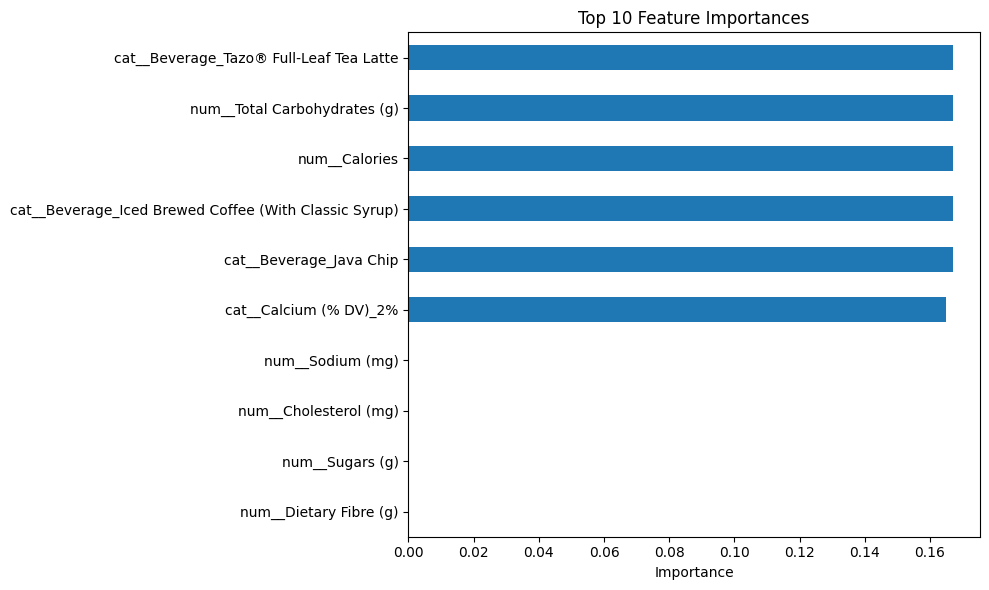

In [2]:
# ==================================================
# DECISION TREE CLASSIFIER - COMPLETE KAGGLE CODE
# ==================================================

import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

# 1. FIND DATASET
files = (
    glob.glob("/kaggle/input/**/*.csv", recursive=True)
    + glob.glob("/kaggle/input/**/*.xlsx", recursive=True)
    + glob.glob("/kaggle/input/**/*.xls", recursive=True)
)

if not files:
    print("ERROR: No CSV or Excel dataset found.")
    print("Upload your dataset to Kaggle's Input section.")
else:
    # 2. LOAD DATASET
    file_path = files[0]
    print("Dataset:", file_path)

    if file_path.endswith(".csv"):
        df = pd.read_csv(file_path)
    else:
        df = pd.read_excel(file_path)

    # 3. BASIC EDA
    print("\nFirst 5 Rows:")
    print(df.head())

    print("\nDataset Shape:", df.shape)
    print("\nColumn Names:", df.columns.tolist())
    print("\nData Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nDuplicate Rows:", df.duplicated().sum())

    print("\nStatistical Summary:")
    print(df.describe(include="all").T)

    # 4. CLEAN DATA
    df.columns = df.columns.astype(str).str.strip()
    df = df.replace([np.inf, -np.inf], np.nan)
    df = df.drop_duplicates()

    # Remove completely empty columns and rows
    df = df.dropna(axis=1, how="all")
    df = df.dropna(axis=0, how="all")

    # SET YOUR TARGET COLUMN HERE
    # None means use the last column automatically.
    TARGET_COLUMN = None

    if df.empty or len(df.columns) < 2:
        print("\nERROR: Dataset must contain rows and at least 2 columns.")
    else:
        if TARGET_COLUMN is None:
            target = df.columns[-1]
            print("\nTarget automatically selected:", target)
        else:
            target = TARGET_COLUMN

        if target not in df.columns:
            print("\nERROR: Target column not found.")
            print("Available columns:", df.columns.tolist())
        else:
            # 5. PREPARE FEATURES AND TARGET
            df = df.dropna(subset=[target])
            X = df.drop(columns=[target]).copy()
            y = df[target].copy()

            # Remove columns that contain no usable values
            X = X.dropna(axis=1, how="all")

            # Remove rows with missing target values already handled
            if X.shape[1] == 0:
                print("\nERROR: No usable feature columns found.")
            elif y.nunique() < 2:
                print("\nERROR: Target must contain at least 2 classes.")
            elif len(df) < 4:
                print("\nERROR: Dataset is too small to split reliably.")
            else:
                # Convert date columns to strings so they can be encoded
                for col in X.select_dtypes(
                    include=["datetime", "datetimetz"]
                ).columns:
                    X[col] = X[col].astype(str)

                # Detect numeric and categorical columns
                numeric_cols = X.select_dtypes(
                    include=["number", "bool"]
                ).columns.tolist()

                categorical_cols = [
                    col for col in X.columns
                    if col not in numeric_cols
                ]

                # 6. PREPROCESS FEATURES
                numeric_pipeline = Pipeline([
                    ("imputer", SimpleImputer(strategy="median"))
                ])

                categorical_pipeline = Pipeline([
                    ("imputer", SimpleImputer(
                        strategy="most_frequent"
                    )),
                    ("encoder", OneHotEncoder(
                        handle_unknown="ignore"
                    ))
                ])

                transformers = []

                if numeric_cols:
                    transformers.append(
                        ("num", numeric_pipeline, numeric_cols)
                    )

                if categorical_cols:
                    transformers.append(
                        ("cat", categorical_pipeline, categorical_cols)
                    )

                preprocessor = ColumnTransformer(
                    transformers=transformers
                )

                # 7. SPLIT DATA
                # Stratify when each class has enough examples
                class_counts = y.value_counts()
                n_test = max(1, int(np.ceil(len(y) * 0.2)))
                n_train = len(y) - n_test

                can_stratify = (
                    class_counts.min() >= 2
                    and n_test >= y.nunique()
                    and n_train >= y.nunique()
                )

                try:
                    X_train, X_test, y_train, y_test = (
                        train_test_split(
                            X,
                            y,
                            test_size=0.2,
                            random_state=RANDOM_STATE,
                            stratify=y if can_stratify else None
                        )
                    )

                    if y_train.nunique() < 2:
                        raise ValueError(
                            "Training split contains fewer than 2 classes."
                        )

                    # 8. BUILD MODEL PIPELINE
                    model = Pipeline([
                        ("preprocessor", preprocessor),
                        ("classifier", DecisionTreeClassifier(
                            max_depth=5,
                            random_state=RANDOM_STATE,
                            class_weight="balanced"
                        ))
                    ])

                    # 9. TRAIN MODEL
                    model.fit(X_train, y_train)

                    # 10. PREDICT AND EVALUATE
                    y_pred = model.predict(X_test)

                    print("\n" + "=" * 40)
                    print("DECISION TREE RESULTS")
                    print("=" * 40)

                    print(
                        f"\nAccuracy: "
                        f"{accuracy_score(y_test, y_pred) * 100:.2f}%"
                    )

                    print("\nClassification Report:")
                    print(classification_report(
                        y_test,
                        y_pred,
                        zero_division=0
                    ))

                    # 11. CONFUSION MATRIX
                    ConfusionMatrixDisplay.from_predictions(
                        y_test,
                        y_pred,
                        xticks_rotation="vertical"
                    )
                    plt.title("Decision Tree - Confusion Matrix")
                    plt.tight_layout()
                    plt.show()

                    # 12. VISUALIZE DECISION TREE
                    fitted_preprocessor = model.named_steps["preprocessor"]
                    fitted_tree = model.named_steps["classifier"]

                    feature_names = (
                        fitted_preprocessor.get_feature_names_out()
                    )

                    # Limit displayed tree complexity for readability
                    plt.figure(figsize=(22, 12))

                    plot_tree(
                        fitted_tree,
                        feature_names=feature_names,
                        class_names=[
                            str(c) for c in fitted_tree.classes_
                        ],
                        filled=True,
                        rounded=True,
                        max_depth=3,
                        fontsize=8
                    )

                    plt.title(
                        "Decision Tree Classifier "
                        "(Top 3 Levels Displayed)"
                    )
                    plt.tight_layout()
                    plt.show()

                    # 13. FEATURE IMPORTANCE
                    importance = pd.Series(
                        fitted_tree.feature_importances_,
                        index=feature_names
                    ).sort_values(ascending=False)

                    print("\nTop 10 Important Features:")
                    print(importance.head(10))

                    top_features = importance.head(10).sort_values()

                    top_features.plot(
                        kind="barh",
                        figsize=(10, 6)
                    )
                    plt.title("Top 10 Feature Importances")
                    plt.xlabel("Importance")
                    plt.tight_layout()
                    plt.show()

                except ValueError as error:
                    print("\nMODEL ERROR:", error)
                    print(
                        "Check the target column, class distribution, "
                        "and dataset size."
                    )
                    

Loading dataset from: /kaggle/input/datasets/henryshan/starbucks/starbucks.csv

DATASET OVERVIEW: 242 rows × 18 columns

--- First 5 Rows ---


,Beverage_category,Beverage,Beverage_prep,Calories,Total Fat (g),Trans Fat (g),Saturated Fat (g),Sodium (mg),Total Carbohydrates (g),Cholesterol (mg),Dietary Fibre (g),Sugars (g),Protein (g),Vitamin A (% DV),Vitamin C (% DV),Calcium (% DV),Iron (% DV),Caffeine (mg)
0,Coffee,Brewed Coffee,Short,3,0.1,0.0,0.0,0,5,0,0,0,0.3,0%,0%,0%,0%,175
1,Coffee,Brewed Coffee,Tall,4,0.1,0.0,0.0,0,10,0,0,0,0.5,0%,0%,0%,0%,260
2,Coffee,Brewed Coffee,Grande,5,0.1,0.0,0.0,0,10,0,0,0,1.0,0%,0%,0%,0%,330
3,Coffee,Brewed Coffee,Venti,5,0.1,0.0,0.0,0,10,0,0,0,1.0,0%,0%,2%,0%,410
4,Classic Espresso Drinks,Caffè Latte,Short Nonfat Milk,70,0.1,0.1,0.0,5,75,10,0,9,6.0,10%,0%,20%,0%,75



--- Data Types & Quality Audit ---
                           Dtype  Non-Null Count  Null Count  Null %  \
Beverage_category         object             242           0    0.00   
Beverage                  object             242           0    0.00   
Beverage_prep             object             242           0    0.00   
Calories                   int64             242           0    0.00   
Total Fat (g)             object             242           0    0.00   
Trans Fat (g)            float64             242           0    0.00   
Saturated Fat (g)        float64             242           0    0.00   
Sodium (mg)                int64             242           0    0.00   
Total Carbohydrates (g)    int64             242           0    0.00   
Cholesterol (mg)           int64             242           0    0.00   
Dietary Fibre (g)          int64             242           0    0.00   
Sugars (g)                 int64             242           0    0.00   
Protein (g)              flo

,count,mean,std,min,25%,50%,75%,max
Calories,242.0,193.871901,102.863303,0.0,120.0,185.0,260.00,510.0
Trans Fat (g),242.0,1.307025,1.640259,0.0,0.1,0.5,2.00,9.0
Saturated Fat (g),242.0,0.037603,0.071377,0.0,0.0,0.0,0.10,0.3
Sodium (mg),242.0,6.363636,8.630257,0.0,0.0,5.0,10.00,40.0
Total Carbohydrates (g),242.0,128.884298,82.303223,0.0,70.0,125.0,170.00,340.0
Cholesterol (mg),242.0,35.991736,20.795186,0.0,21.0,34.0,50.75,90.0
Dietary Fibre (g),242.0,0.805785,1.445944,0.0,0.0,0.0,1.00,8.0
Sugars (g),242.0,32.962810,19.730199,0.0,18.0,32.0,43.75,84.0
Protein (g),242.0,6.978512,4.871659,0.0,3.0,6.0,10.00,20.0
Vitamin A (% DV),242.0,9.830579,8.097962,0.0,4.0,8.0,15.00,50.0


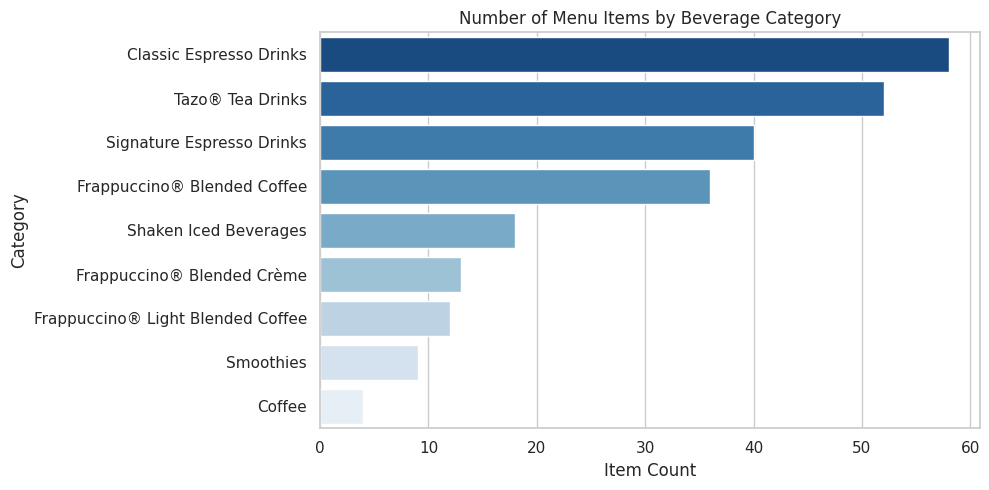

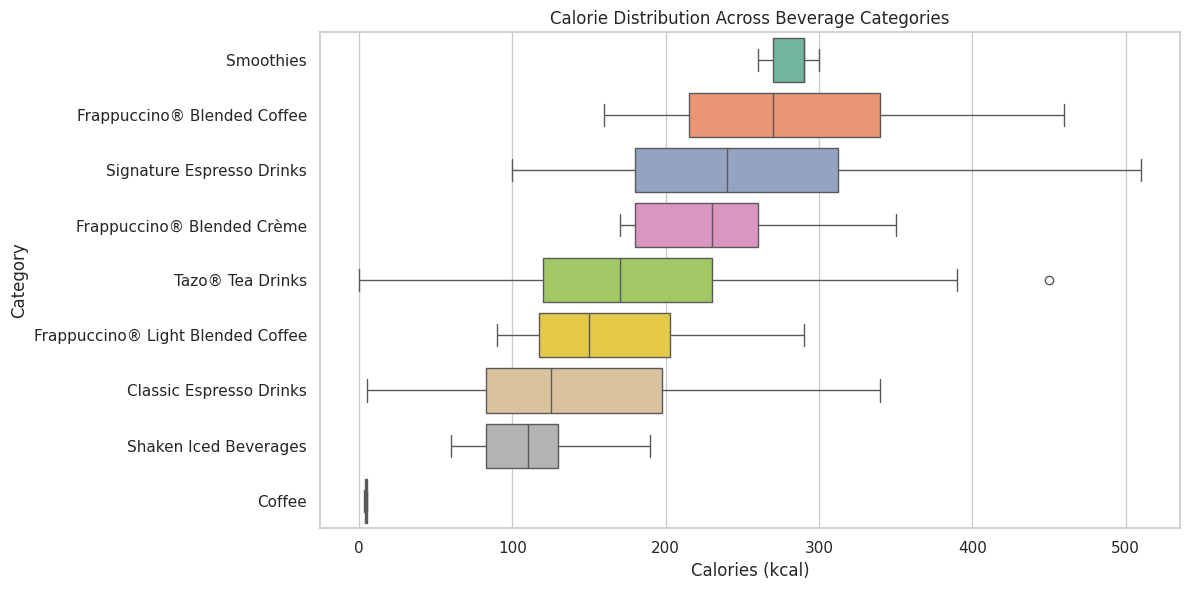

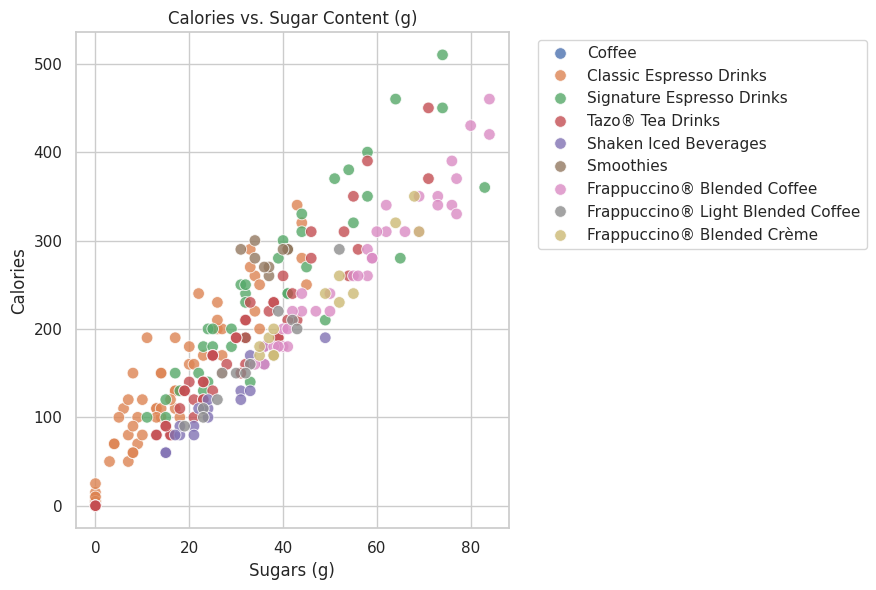

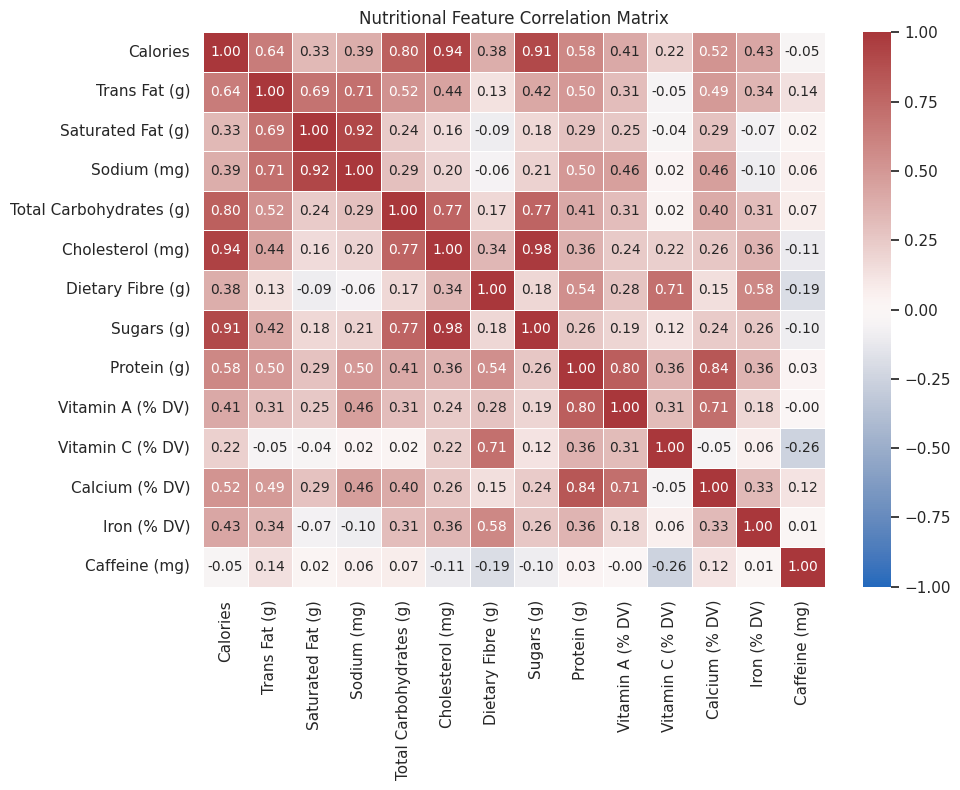

In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting defaults
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10

file_path = '/kaggle/input/datasets/henryshan/starbucks/starbucks.csv'

# Fallback path search if file structure varies in Kaggle input
if not os.path.exists(file_path):
    for root, _, files in os.walk('/kaggle/input'):
        for f in files:
            if f.lower() == 'starbucks.csv':
                file_path = os.path.join(root, f)
                break

print(f"Loading dataset from: {file_path}")
df = pd.read_csv(file_path)

# ==========================================
# 1. DATA OVERVIEW & CLEANING
# ==========================================
print("\n" + "="*50)
print(f"DATASET OVERVIEW: {df.shape[0]} rows × {df.shape[1]} columns")
print("="*50)

# Clean column names (strip whitespace)
df.columns = df.columns.str.strip()

print("\n--- First 5 Rows ---")
display(df.head())

print("\n--- Data Types & Quality Audit ---")
audit_df = pd.DataFrame({
    'Dtype': df.dtypes,
    'Non-Null Count': df.notnull().sum(),
    'Null Count': df.isnull().sum(),
    'Null %': (df.isnull().sum() / len(df) * 100).round(2),
    'Unique Values': df.nunique()
})
print(audit_df)
print(f"\nTotal Duplicate Rows: {df.duplicated().sum()}")

# Clean numeric columns containing strings/percentages (e.g., Vitamin columns or Caffeine)
cols_to_clean = ['Iron (% DV)', 'Vitamin A (% DV)', 'Vitamin C (% DV)', 'Calcium (% DV)', 'Caffeine (mg)']
for col in cols_to_clean:
    if col in df.columns and df[col].dtype == 'object':
        # Convert strings, remove %, replace non-numeric markers like 'Varies' or 'varies' with NaN
        df[col] = df[col].astype(str).str.replace('%', '').str.strip()
        df[col] = pd.to_numeric(df[col], errors='coerce')

# ==========================================
# 2. NUMERICAL & CATEGORICAL STATS
# ==========================================
print("\n" + "="*50)
print("SUMMARY STATISTICS (NUMERICAL)")
print("="*50)
display(df.describe().T)

num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

# ==========================================
# 3. VISUALIZATIONS
# ==========================================

# A. Beverage Category Count
if 'Beverage_category' in df.columns:
    plt.figure(figsize=(10, 5))
    order = df['Beverage_category'].value_counts().index
    ax = sns.countplot(data=df, y='Beverage_category', order=order, palette='Blues_r')
    plt.title('Number of Menu Items by Beverage Category')
    plt.xlabel('Item Count')
    plt.ylabel('Category')
    plt.tight_layout()
    plt.show()

# B. Calorie Distribution by Category
if 'Calories' in df.columns and 'Beverage_category' in df.columns:
    plt.figure(figsize=(12, 6))
    cat_order = df.groupby('Beverage_category')['Calories'].median().sort_values(ascending=False).index
    sns.boxplot(data=df, y='Beverage_category', x='Calories', order=cat_order, palette='Set2')
    plt.title('Calorie Distribution Across Beverage Categories')
    plt.xlabel('Calories (kcal)')
    plt.ylabel('Category')
    plt.tight_layout()
    plt.show()

# C. Relationship: Calories vs. Sugars
if 'Calories' in df.columns and 'Sugars (g)' in df.columns:
    plt.figure(figsize=(9, 6))
    sns.scatterplot(
        data=df, 
        x='Sugars (g)', 
        y='Calories', 
        hue='Beverage_category' if 'Beverage_category' in df.columns else None,
        s=70, 
        alpha=0.8
    )
    plt.title('Calories vs. Sugar Content (g)')
    plt.xlabel('Sugars (g)')
    plt.ylabel('Calories')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

# D. Feature Correlation Matrix
if len(num_cols) > 1:
    plt.figure(figsize=(10, 8))
    sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, linewidths=0.5)
    plt.title('Nutritional Feature Correlation Matrix')
    plt.tight_layout()
    plt.show()
    